In [1]:
import pandas as pd
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/diabetes.csv') 


In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<Axes: >

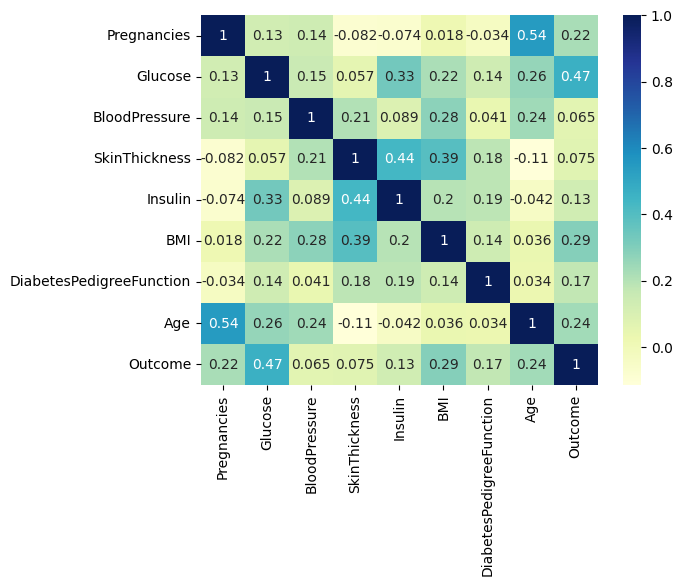

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.heatmap(df.corr(), annot=True, cmap="YlGnBu")


In [6]:
x = df.drop('Outcome', axis = 1)

In [7]:
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [8]:
y = df['Outcome']

In [9]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [10]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
x_scaled = ss.fit_transform(x)


In [11]:
x_scaled.shape

(768, 8)

In [12]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x_scaled,y,test_size = 0.2,random_state = 42)

In [13]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense as dense
from tensorflow.keras.optimizers import Adam,Adagrad,RMSprop

In [14]:
!pip install -q keras-tuner
import keras_tuner as kt

In [15]:

def build_model(hp):
    model = Sequential()
    model.add(dense(32,activation='relu',input_shape=(8,)))
   
    model.add(dense(1,activation='sigmoid'))
    optimizers = hp.Choice('optimizers',values =  ['adam','sgd','rmsprop','adadelta'])
    model.compile(loss='binary_crossentropy', optimizer = optimizers, metrics = ['accuracy'])
    return model

In [16]:
tuner = kt.RandomSearch(build_model, objective='val_accuracy', max_trials = 4,directory = 'mydir',project_name = 'kshitizkandel')

Reloading Tuner from mydir/kshitizkandel/tuner0.json


In [17]:
tuner.search(x_train,y_train,epochs=10,validation_data=(x_test,y_test))

In [18]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
best_hp.values


{'optimizers': 'rmsprop'}

In [19]:
model = tuner.hypermodel.build(best_hp)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
history = model.fit(x_train,y_train,epochs=200,validation_data=(x_test,y_test),initial_epoch=6)

Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7020 - loss: 0.6151 - val_accuracy: 0.7273 - val_loss: 0.5977
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7394 - loss: 0.5695 - val_accuracy: 0.7597 - val_loss: 0.5714
Epoch 9/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7443 - loss: 0.5426 - val_accuracy: 0.7597 - val_loss: 0.5523
Epoch 10/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7557 - loss: 0.5220 - val_accuracy: 0.7532 - val_loss: 0.5361
Epoch 11/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7590 - loss: 0.5047 - val_accuracy: 0.7468 - val_loss: 0.5237
Epoch 12/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7606 - loss: 0.4924 - val_accuracy: 0.7468 - val_loss: 0.5149
Epoch 13/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7720 - loss: 0.4830 - val_accuracy: 0.7597 - val_loss: 0.5092
Epoch 14/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7704 - loss: 0.4756 - val_accuracy: 0.76

In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

def build_model(hp):

    model = Sequential()

    # Tune the number of hidden layers
    num_layers = hp.Int(
        'layers',
        min_value=2,
        max_value=8,
        step=1
    )

    # Create hidden layers
    for i in range(num_layers):

        # Tune number of neurons
        units = hp.Int(
            f'layer_{i}',
            min_value=8,
            max_value=256,
            step=32
        )

        # Tune activation function
        activation = hp.Choice(
            f'activation_{i}',
            values=['relu', 'tanh', 'sigmoid']
        )

        if i == 0:
            model.add(Dense(units,
                            activation=activation,
                            input_shape=(8,)))
        else:
            model.add(Dense(units,
                            activation=activation))

    # Output layer
    model.add(Dense(1, activation='sigmoid'))

    # Tune optimizer
    optimizer = hp.Choice(
        f'optimizer_{i}',
        values=['adam', 'sgd', 'rmsprop', 'adadelta']
    )

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [27]:
tuner = kt.RandomSearch(build_model,objective='val_accuracy', max_trials = 4, overwrite=True)

In [28]:
tuner.search(x_train,y_train,epochs=10,validation_data=(x_test,y_test))


Trial 4 Complete [00h 00m 05s]
val_accuracy: 0.7922077775001526

Best val_accuracy So Far: 0.7922077775001526
Total elapsed time: 00h 00m 22s


In [29]:
tuner.get_best_hyperparameters()[0].values

{'layers': 3,
 'layer_0': 104,
 'activation_0': 'sigmoid',
 'layer_1': 104,
 'activation_1': 'relu',
 'optimizer_1': 'adam',
 'layer_2': 200,
 'activation_2': 'tanh',
 'layer_3': 200,
 'activation_3': 'tanh',
 'layer_4': 200,
 'activation_4': 'relu',
 'layer_5': 168,
 'activation_5': 'tanh',
 'layer_6': 104,
 'activation_6': 'relu',
 'layer_7': 104,
 'activation_7': 'sigmoid',
 'optimizer_7': 'sgd',
 'optimizer_2': 'adam'}

In [30]:
best_model = tuner.get_best_models(num_models=1)[0]

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [31]:
history1 = best_model.fit(x_train,y_train,epochs=200,validation_data=(x_test,y_test))

Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7622 - loss: 0.4726 - val_accuracy: 0.7662 - val_loss: 0.5055
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7622 - loss: 0.4739 - val_accuracy: 0.7597 - val_loss: 0.4976
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7752 - loss: 0.4603 - val_accuracy: 0.7597 - val_loss: 0.5127
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7671 - loss: 0.4586 - val_accuracy: 0.7792 - val_loss: 0.5085
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7752 - loss: 0.4600 - val_accuracy: 0.7857 - val_loss: 0.5142
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7720 - loss: 0.4703 - val_accuracy: 0.7468 - val_loss: 0.5096
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7655 - loss: 0.4668 - val_accuracy: 0.7403 - val_loss: 0.5073
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7752 - loss: 0.4469 - val_accuracy: 0.7078 - 